<a href="https://colab.research.google.com/github/olha-pelykh/AI_Lab3/blob/main/lab3_variant12_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Google Drive і структура проєкту
Усе зберігається на Drive, щоб не зникло після перезапуску Colab.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/UNIK/SEM 7/ШІ/LAB 3'
for sub in ['data/synthetic', 'data/open', 'data/own', 'results', 'figures', 'tessdata_best']:
    os.makedirs(os.path.join(PROJECT, sub), exist_ok=True)
os.chdir(PROJECT)
print('Робоча папка:', os.getcwd())

Mounted at /content/drive
Робоча папка: /content/drive/MyDrive/UNIK/SEM 7/ШІ/LAB 3


## 2. Встановлення Tesseract 5



In [12]:
!sudo add-apt-repository -y ppa:alex-p/tesseract-ocr5 > /dev/null 2>&1
!sudo apt-get update -qq
!sudo apt-get install -y -qq tesseract-ocr tesseract-ocr-ukr tesseract-ocr-eng fonts-dejavu-core > /dev/null
!tesseract --version | head -1
!tesseract --list-langs

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 5.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
tesseract 5.5.1
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
osd
ukr


Точніші моделі **tessdata_best**. Завантажуються один раз на Drive.

In [13]:
TESSDATA_BEST = os.path.join(PROJECT, 'tessdata_best')
for lang in ['ukr', 'eng', 'osd']:
    path = os.path.join(TESSDATA_BEST, f'{lang}.traineddata')
    if not os.path.exists(path):
        !wget -q -O "{path}" https://github.com/tesseract-ocr/tessdata_best/raw/main/{lang}.traineddata
print(os.listdir(TESSDATA_BEST))

['ukr.traineddata', 'eng.traineddata', 'osd.traineddata']


## 3. Бібліотеки Python


In [14]:
!pip install -q pytesseract rapidfuzz easyocr datasets jiwer
!pip install -q paddlepaddle paddleocr

## 4. Персональні параметри

In [7]:
STUDENT    = 'Пелих'
VARIANT    = 12
STUDENT_ID = 978
SEED = 1000 * VARIANT + STUDENT_ID
print('SEED =', SEED)

SEED = 12978


## 5. Перевірка, що все працює

In [11]:
import os, time, json
import numpy as np, cv2, pytesseract, paddleocr
from PIL import Image, ImageDraw, ImageFont

print('Tesseract:', pytesseract.get_tesseract_version())
print('PaddleOCR:', paddleocr.__version__)

font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', 36)
img = Image.new('RGB', (900, 140), 'white')
d = ImageDraw.Draw(img)
d.text((20, 15), 'Тіні забутих предків', font=font, fill='black')
d.text((20, 75), 'TOTAL 45,000  CASH 50.000', font=font, fill='black')
img.save('results/test.png')
display(img)

TESS_CFG = f'--oem 1 --psm 6 --tessdata-dir "{TESSDATA_BEST}"'
print('Tesseract ukr+eng:', pytesseract.image_to_string(img, lang='ukr+eng', config=TESS_CFG))

ModuleNotFoundError: No module named 'pytesseract'

In [9]:
from paddleocr import PaddleOCR
arr = np.array(img)[:, :, ::-1]

ocr_en = PaddleOCR(
    lang='en',
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)
t = time.time()
res = ocr_en.predict(arr)
print(res[0]['rec_texts'], [round(float(s), 3) for s in res[0]['rec_scores']])
print(f'час: {time.time()-t:.2f} c')

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


['  ', 'TOTAL 45,000 CASH 50.000'] [0.992, 0.993]
час: 3.31 c


In [11]:
ocr_uk = PaddleOCR(
    lang='uk',
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)
t = time.time()
res = ocr_uk.predict(arr)
print(res[0]['rec_texts'], [round(float(s), 3) for s in res[0]['rec_scores']])
print(f'час: {time.time()-t:.2f} c')

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv5_server_det`.
Creating model: ('eslav_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/eslav_PP-OCRv5_mobile_rec`.


['Тіні забутих предків', 'TOTAL 45,000 CASH 50.000'] [0.977, 0.991]
час: 3.21 c


## 6. Відкритий набір CORD v2
Еталон лежить у полі `ground_truth` як JSON-рядок; текст рядків — у `valid_line[*].words[*].text`.
CORD містить цілі чеки (сторінки); беремо їх детерміновано за SEED.

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-7dbbe248962764(…): reconstructing file:   0%|          |  0.00B /  441MB            

data/train-00001-of-00004-7dbbe248962764(…): downloading bytes:           |  0.00B            

... (8 outputs left out)

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'ground_truth'],
    num_rows: 100
})
{'image': Image(mode=None, decode=True), 'ground_truth': Value('string')}
Збережено зразки: [9, 18, 24, 26, 35, 49, 50, 51, 53, 56, 58, 59, 62, 69, 74, 75, 77, 80, 87, 93]


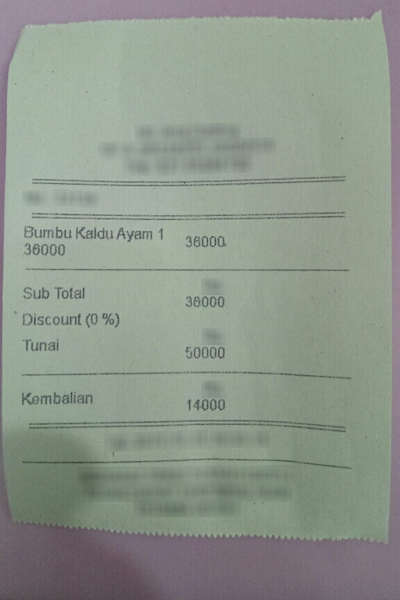

Bumbu Kaldu Ayam 1 36000
36000
Sub Total
36000
Discount (0%)
Tunai
50000
Kembalian 14000


In [12]:
from datasets import load_dataset
cord = load_dataset('naver-clova-ix/cord-v2', split='test')
print(cord)
print(cord.features)

def cord_lines(sample):
    gt = json.loads(sample['ground_truth'])
    lines = {}
    for vl in gt['valid_line']:
        for w in vl['words']:
            lines.setdefault(w['row_id'], []).append(w['text'])
    return [' '.join(ws) for _, ws in sorted(lines.items())]

rng = np.random.default_rng(SEED)
ids = sorted(rng.choice(len(cord), size=20, replace=False).tolist())
json.dump(ids, open('data/open/cord_ids.json', 'w'))

for i in ids:
    s = cord[i]
    s['image'].save(f'data/open/cord_{i:03d}.png')
    open(f'data/open/cord_{i:03d}.txt', 'w', encoding='utf-8').write('\n'.join(cord_lines(s)))
print('Збережено зразки:', ids)
display(cord[ids[0]]['image'].resize((400, int(400*cord[ids[0]]['image'].height/cord[ids[0]]['image'].width))))
print('\n'.join(cord_lines(cord[ids[0]])))

## 7. Деградація JPEG (чинник варіанта 12)

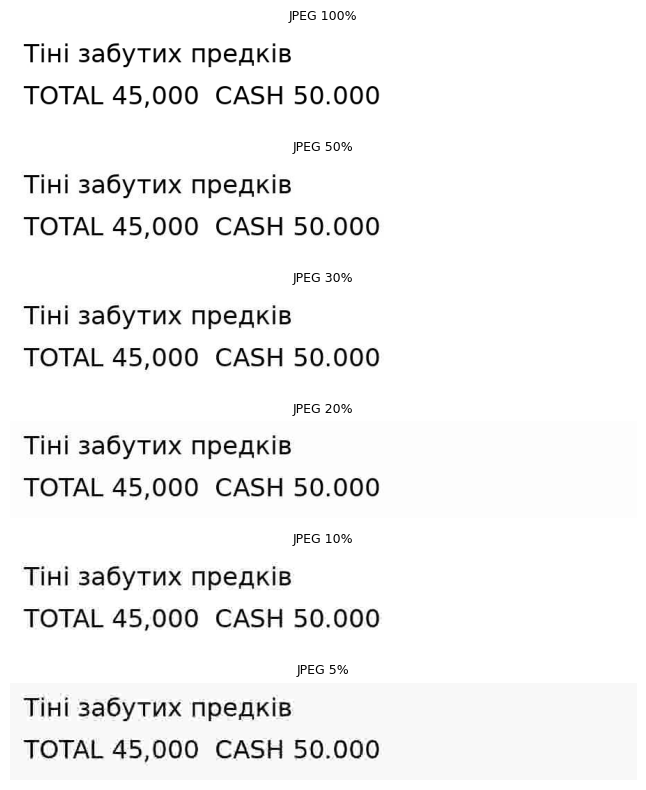

In [13]:
JPEG_LEVELS = [100, 50, 30, 20, 10, 5]

def degrade_jpeg(img_bgr, quality):
    ok, buf = cv2.imencode('.jpg', img_bgr, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    return cv2.imdecode(buf, cv2.IMREAD_COLOR)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(len(JPEG_LEVELS), 1, figsize=(8, 8))
for ax, q in zip(axes, JPEG_LEVELS):
    ax.imshow(degrade_jpeg(arr, q)[:, :, ::-1]); ax.set_title(f'JPEG {q}%', fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 8. Git-репозиторій (на Drive)


In [14]:
from google.colab import userdata
GH_USER = 'olha-pelykh'
GH_REPO = 'AI_Lab3'
token = userdata.get('GH_TOKEN')

REPO_DIR = '/content/drive/MyDrive/ocr_lab3_repo'
if not os.path.exists(REPO_DIR):
    !git clone https://{token}@github.com/{GH_USER}/{GH_REPO}.git "{REPO_DIR}"
%cd "{REPO_DIR}"
!git config user.name "{STUDENT}"
!git config user.email "you@example.com"

Cloning into '/content/drive/MyDrive/ocr_lab3_repo'...
/content/drive/MyDrive/ocr_lab3_repo


In [ ]:
!git add -A
!git commit -m "Початкове налаштування середовища"
!git push

## Гіпотези до експерименту

**H1. Крива стійкості до JPEG.** На синтетичному наборі при якості JPEG 100–30 % обидва інструменти матимуть CER не більше 3 %. CER Tesseract вперше перевищить 10 % при якості 10 %, а PaddleOCR залишиться нижче 10 % навіть при 5 %, бо Tesseract залежить від бінаризації, яку блокові артефакти JPEG руйнують, а PaddleOCR навчений на зображеннях з шумами та стисненням.

**H2. Чеки CORD.** На відкритих чеках CER Tesseract (15–25 %) буде вищим, ніж у PaddleOCR (5–10 %), бо чеки сфотографовані з нахилом, тінями і розмиттям, а Tesseract слабший на фото й складній верстці, тоді як PaddleOCR має окремий нейромережевий детектор тексту.

**H3. Цифри та ціни.** CER, обчислений лише за цифрами і цінами, буде нижчим за загальний CER для обох інструментів, бо цифр лише десять і вони відрізняються між собою сильніше, ніж літери.

**H4. Власні чеки, пересняті з екрана.** CER на них буде у 2–4 рази вищим, ніж на оригінальних чеках CORD, бо додаються муар від пікселів екрана, відблиски та повторне стиснення.

**H5. Рукопис.** CER на рукописній сторінці перевищить 30 % для обох інструментів, бо вони навчені на друкованому тексті.


Вибір 40 рядків і хеш еталону

In [8]:
import re, json, hashlib, unicodedata
import numpy as np

raw = open('data/synthetic/kotsiubynsky.txt', encoding='utf-8').read()
raw = unicodedata.normalize('NFC', raw)
sentences = [s.strip() for s in re.split(r'(?<=[.!?…])\s+', raw.replace('\n', ' '))]
pool = [s for s in sentences if 40 <= len(s) <= 70]
print('Кандидатів:', len(pool))

rng = np.random.default_rng(SEED)
idx = sorted(rng.choice(len(pool), size=40, replace=False).tolist())
lines = [pool[i] for i in idx]

with open('data/synthetic/ground_truth.json', 'w', encoding='utf-8') as f:
    json.dump({'seed': SEED, 'variant': VARIANT, 'lines': lines}, f, ensure_ascii=False, indent=1)

sha = hashlib.sha256(open('data/synthetic/ground_truth.json', 'rb').read()).hexdigest()
print('SHA-256 еталону:', sha)

Кандидатів: 344
SHA-256 еталону: 67c461a34d86b4db4fee18e7f7261860422f488d4cb46080b7083a7e453a94f5


Зображення на 6 рівнях JPEG

In [19]:
import os, time, json
import numpy as np, cv2, pytesseract
from PIL import Image, ImageDraw, ImageFont
JPEG_LEVELS = [100, 50, 30, 20, 10, 5]
font_size = int(np.random.default_rng(SEED).integers(30, 41))
font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', font_size)

def render_line(text):
    w = int(font.getlength(text)) + 40
    img = Image.new('RGB', (w, font_size + 40), 'white')
    ImageDraw.Draw(img).text((20, 20), text, font=font, fill='black')
    return np.array(img)[:, :, ::-1]            # BGR

def degrade_jpeg(img_bgr, q):
    ok, buf = cv2.imencode('.jpg', img_bgr, [cv2.IMWRITE_JPEG_QUALITY, int(q)])
    return cv2.imdecode(buf, cv2.IMREAD_COLOR)

for i, t in enumerate(lines):
    base = render_line(t)
    for q in JPEG_LEVELS:
        cv2.imwrite(f'data/synthetic/line{i:02d}_q{q:03d}.jpg', base, [cv2.IMWRITE_JPEG_QUALITY, q])
print('Створено зображень:', len(lines) * len(JPEG_LEVELS))

Створено зображень: 240


Метрики CER, WER, CER для цифр

In [20]:
from rapidfuzz.distance import Levenshtein

def normalize(s):
    s = unicodedata.normalize('NFC', s)
    s = re.sub(r"[’ʼ'`]", "'", s)
    return re.sub(r'\s+', ' ', s).strip()

def cer(ref, hyp):
    ref, hyp = normalize(ref), normalize(hyp)
    return Levenshtein.distance(ref, hyp) / max(len(ref), 1)

def wer(ref, hyp):
    r, h = normalize(ref).split(), normalize(hyp).split()
    return Levenshtein.distance(r, h) / max(len(r), 1)

def numbers(s):
    return ' '.join(re.findall(r'\d+(?:[.,]\d+)*', normalize(s)))

def cer_numbers(ref, hyp):
    return cer(numbers(ref), numbers(hyp))


print(cer('інженерія даних', 'інженерія даиих'), wer('інженерія даних', 'інженерія даиих'))

0.06666666666666667 0.5


Перший прогін на синтетиці

In [22]:
from paddleocr import PaddleOCR
import pandas as pd, time
TESS_CFG = f'--oem 1 --psm 7 --tessdata-dir "{TESSDATA_BEST}"'
ocr_uk = PaddleOCR(lang='uk', enable_mkldnn=False, use_doc_orientation_classify=False,
                   use_doc_unwarping=False, use_textline_orientation=False)

def run_tess(img):
    d = pytesseract.image_to_data(img, lang='ukr+eng', config=TESS_CFG, output_type=pytesseract.Output.DICT)
    words = [(w, float(c)) for w, c in zip(d['text'], d['conf']) if w.strip() and float(c) >= 0]
    return ' '.join(w for w, _ in words), (np.mean([c for _, c in words]) / 100 if words else 0.0)

def run_paddle(img):
    r = ocr_uk.predict(img)[0]
    return ' '.join(r['rec_texts']), (float(np.mean(r['rec_scores'])) if len(r['rec_scores']) else 0.0)

rows = []
for i, ref in enumerate(lines):
    for q in JPEG_LEVELS:
        img = cv2.imread(f'data/synthetic/line{i:02d}_q{q:03d}.jpg')
        for name, fn in [('Tesseract', run_tess), ('PaddleOCR', run_paddle)]:
            t0 = time.perf_counter(); hyp, conf = fn(img); dt = time.perf_counter() - t0
            rows.append(dict(line=i, q=q, tool=name, ref=ref, hyp=hyp, conf=conf,
                             cer=cer(ref, hyp), wer=wer(ref, hyp), sec=dt))
df = pd.DataFrame(rows)
df.to_csv('results/synthetic_results.csv', index=False)
print(df.groupby(['tool', 'q'])[['cer', 'wer', 'sec']].mean().round(3))

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv5_server_det', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-OCRv5_server_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv5_server_det`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('eslav_PP-OCRv5_mobile_rec', None, None)
Using official model (eslav_PP-OCRv5_mobile_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/eslav_PP-OCRv5_mobile_rec`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

                 cer    wer    sec
tool      q                       
PaddleOCR 5    0.009  0.036  1.609
          10   0.005  0.019  1.546
          20   0.007  0.034  1.619
          30   0.008  0.038  1.623
          50   0.009  0.051  1.695
          100  0.010  0.048  1.644
Tesseract 5    0.011  0.038  0.618
          10   0.007  0.026  0.597
          20   0.008  0.030  0.639
          30   0.008  0.029  0.647
          50   0.009  0.032  0.639
          100  0.008  0.029  0.707
